In [2]:
# ANA500 Micro-Project 3
# Predicting E-Commerce Shipping Costs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Check the current folder and available files

import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
for file in os.listdir():
    print(file)

Current folder:
/Users/karissavoetberg/Downloads

Files in this folder:
CoverLetterExamples.docx
Belt-Movement-Walking_6Ext10-0270.wav
4-11.pdf
googlechrome.dmg
captions_Stepe_2.vtt
.Rhistory
IMG_0401.heic
6-OOP-PolymorphismAnd Inheritance.pdf
3-BasicProgrammingConcepts2.pdf
maudioplugins_16_08_setupmac.app
d3b4a7e7-3663-43de-8204-ea49e080c150.pdf
1-JavaFundamentals.pdf
~$ogress Check #4 v1.0.docx
VoxengoSPAN_319_Mac_AU_AAX_setup.dmg
WanderingPulsingEner CE1441-44k.wav
Grammarly.o0.cu9GZ961zvaga9va54nc00g2.dmg
DemonGrowlHover5 SDT2034205.wav
ZombieCryLower PE981202_1.wav
Low Roar Pro Tools Demo
Creak-Wood-Chair_6Ext10-0936.wav
Avid_Link_24.5.0_Mac.pkg
ANA500_Micro-Project_template.pptx
KarissaVoetberg_ANA500_MicroProject3.html
KarissaVoetberg_ANA500_MicroProject1_Code.pdf
next_tooclose.mid
Source.cpp
ch07-Pointers & Structures.pptx
WwiseLauncher-2.pkg
WoodRattle FS10_97_2.wav
Music Theory
Hit-Robot-Metallic_NITRO2-214.wav
ableton_live_suite_11.3.12_universal.dmg
AP4o_1.2_GROOVE.numbers

In [11]:
# Step 3: Load both datasets

import pandas as pd

# Load datasets from the Micro-Project1 folder
order_items = pd.read_csv(
    "Micro-Project1/olist_order_items_dataset.csv.zip"
)

products = pd.read_csv(
    "Micro-Project1/olist_products_dataset.csv.zip"
)

# Check that both datasets loaded
print("Order Items Dataset:", order_items.shape)
print("Products Dataset:", products.shape)

# Preview the datasets
display(order_items.head())
display(products.head())

Order Items Dataset: (112650, 7)
Products Dataset: (32951, 9)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [12]:
# Step 4: Merge the two datasets

# Combine order information with product information
df = pd.merge(
    order_items,
    products,
    on="product_id",
    how="inner"
)

# Check the combined dataset
print("Combined Dataset Shape:", df.shape)

# Display the first five rows
display(df.head())

# Check the columns
print("\nColumn Names:")
print(df.columns.tolist())

Combined Dataset Shape: (112650, 15)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0



Column Names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [15]:
# Step 5: Check missing values

model_columns = ["freight_value", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]

model_df = df[model_columns].copy()

print("Missing Values:")
print(model_df.isnull().sum())

print("\nDataset Information:")
model_df.info()

print("\nSummary Statistics:")
display(model_df.describe())

Missing Values:
freight_value         0
product_weight_g     18
product_length_cm    18
product_height_cm    18
product_width_cm     18
dtype: int64

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 5 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   freight_value      112650 non-null  float64
 1   product_weight_g   112632 non-null  float64
 2   product_length_cm  112632 non-null  float64
 3   product_height_cm  112632 non-null  float64
 4   product_width_cm   112632 non-null  float64
dtypes: float64(5)
memory usage: 4.3 MB

Summary Statistics:


,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112650.000000,112632.000000,112632.000000,112632.000000,112632.000000
mean,19.990320,2093.672047,30.153669,16.593766,22.996546
std,15.806405,3751.596884,16.153449,13.443483,11.707268
min,0.000000,0.000000,7.000000,2.000000,6.000000
25%,13.080000,300.000000,18.000000,8.000000,15.000000
50%,16.260000,700.000000,25.000000,13.000000,20.000000
75%,21.150000,1800.000000,38.000000,20.000000,30.000000
max,409.680000,40425.000000,105.000000,105.000000,118.000000


In [16]:

# Step 6: Clean the dataset for regression

# Remove rows with missing values
clean_df = model_df.dropna().copy()

# Remove invalid zero or negative measurements
clean_df = clean_df[
    (clean_df["product_weight_g"] > 0) &
    (clean_df["product_length_cm"] > 0) &
    (clean_df["product_height_cm"] > 0) &
    (clean_df["product_width_cm"] > 0) &
    (clean_df["freight_value"] >= 0)
].copy()

# Compare the dataset before and after cleaning
print("Original rows:", len(model_df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(model_df) - len(clean_df))

# Confirm there are no missing values
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

# Preview the cleaned dataset
display(clean_df.head())

Original rows: 112650
Cleaned rows: 112624
Rows removed: 26

Missing values after cleaning:
freight_value        0
product_weight_g     0
product_length_cm    0
product_height_cm    0
product_width_cm     0
dtype: int64


,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,13.29,650.0,28.0,9.0,14.0
1,19.93,30000.0,50.0,30.0,40.0
2,17.87,3050.0,33.0,13.0,33.0
3,12.79,200.0,16.0,10.0,15.0
4,18.14,3750.0,35.0,40.0,30.0


In [17]:
# Step 7: Prepare training and testing data

# Select a reproducible sample of 5,000 observations
sample_df = clean_df.sample(n=5000, random_state=42)

# Select predictor variables
features = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

X = sample_df[features]

# Select the value we want to predict
y = sample_df["freight_value"]

# Split the dataset into training and testing groups
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("\nPredictor variables:")
print(X.columns.tolist())

Training observations: 4000
Testing observations: 1000

Predictor variables:
['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [18]:
# Step 8: Train the Linear Regression model

# Create the model
linear_model = LinearRegression()

# Train the model using the training data
linear_model.fit(X_train, y_train)

# Predict shipping costs for the test data
linear_predictions = linear_model.predict(X_test)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results:")
print("Mean Absolute Error:", round(linear_mae, 2))
print("Mean Squared Error:", round(linear_mse, 2))
print("R-squared:", round(linear_r2, 4))

# Compare actual and predicted shipping costs
results = pd.DataFrame({
    "Actual Shipping Cost": y_test,
    "Predicted Shipping Cost": linear_predictions
})

print("\nSample Predictions:")
display(results.head(10))

Linear Regression Results:
Mean Absolute Error: 6.91
Mean Squared Error: 140.92
R-squared: 0.4885

Sample Predictions:


,Actual Shipping Cost,Predicted Shipping Cost
18199,47.41,22.963864
4479,9.24,16.605732
50424,16.49,49.162029
56421,47.24,32.861477
39607,24.09,15.825555
35711,22.67,17.177096
86086,0.00,15.611419
30463,23.32,14.818257
46867,9.34,14.973421
42978,17.69,14.687533


In [19]:

# Step 9: Train the Support Vector Regression model

# Standardize the predictor variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create the SVR model
svr_model = SVR(kernel="rbf")

# Train the model
svr_model.fit(X_train_scaled, y_train)

# Predict shipping costs
svr_predictions = svr_model.predict(X_test_scaled)

# Evaluate the SVR model
svr_mae = mean_absolute_error(y_test, svr_predictions)
svr_mse = mean_squared_error(y_test, svr_predictions)
svr_r2 = r2_score(y_test, svr_predictions)

print("Support Vector Regression Results:")
print("Mean Absolute Error:", round(svr_mae, 2))
print("Mean Squared Error:", round(svr_mse, 2))
print("R-squared:", round(svr_r2, 4))

Support Vector Regression Results:
Mean Absolute Error: 7.17
Mean Squared Error: 208.36
R-squared: 0.2437


Model Performance Comparison:


,Model,MAE,MSE,R-squared
0,Linear Regression,6.9083,140.9218,0.4885
1,SVR,7.1674,208.3632,0.2437


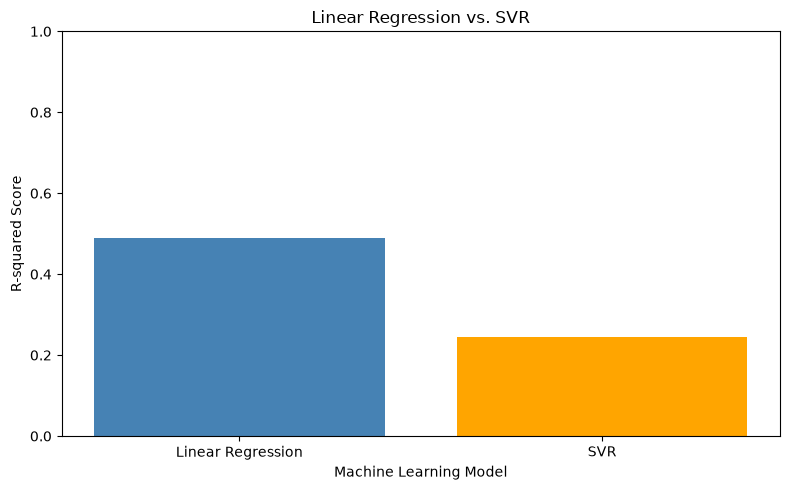

In [20]:

# Step 10: Compare model performance

# Create a table of model results
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "SVR"],
    "MAE": [linear_mae, svr_mae],
    "MSE": [linear_mse, svr_mse],
    "R-squared": [linear_r2, svr_r2]
})

print("Model Performance Comparison:")
display(comparison.round(4))

# Create a bar chart comparing R-squared values
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["R-squared"],
    color=["steelblue", "orange"]
)

plt.title("Linear Regression vs. SVR")
plt.ylabel("R-squared Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

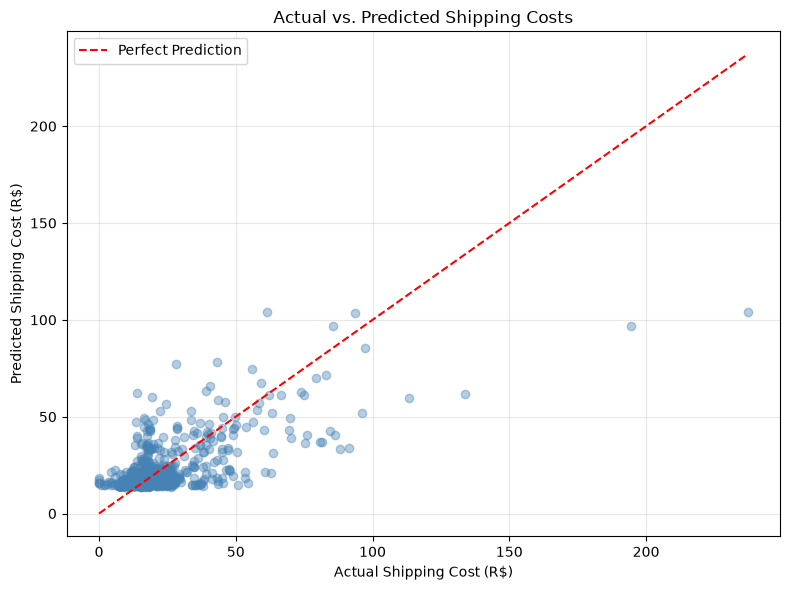

In [21]:
# Step 11: Actual vs. Predicted Shipping Costs

plt.figure(figsize=(8, 6))

# Plot actual and predicted values
plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.4,
    color="steelblue"
)

# Draw the perfect prediction reference line
minimum = min(y_test.min(), linear_predictions.min())
maximum = max(y_test.max(), linear_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs. Predicted Shipping Costs")
plt.xlabel("Actual Shipping Cost (R$)")
plt.ylabel("Predicted Shipping Cost (R$)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()


## Micro-Project 4: Deep Learning Regression

### Predicting E-Commerce Shipping Costs Using Neural Networks

This section extends the previous regression analysis by applying a deep learning neural network to predict shipping costs using product characteristics.

The goal is to compare the neural network with Linear Regression and Support Vector Regression (SVR) to determine which model provides more accurate shipping cost predictions.

The analysis will use TensorFlow and Keras to build, train, and evaluate a neural network regression model.

In [22]:

# Micro-Project 4: Deep Learning Regression
# Import libraries needed to build a neural network

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow and Keras are used for deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Tools for preparing and evaluating our model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set random seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Deep learning libraries imported successfully!")

TensorFlow version: 2.21.0
Deep learning libraries imported successfully!


In [23]:
# Step 1: Prepare data for deep learning

# Remove rows with missing values
deep_df = model_df.dropna().copy()

# Separate the predictors and target
X = deep_df[
    ["product_weight_g",
     "product_length_cm",
     "product_height_cm",
     "product_width_cm"]
]

y = deep_df["freight_value"]

# Check the dataset
print("Dataset shape:", deep_df.shape)
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (112632, 5)
Predictor shape: (112632, 4)
Target shape: (112632,)


In [24]:
# Step 2: Split and scale the data

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Standardize the predictor variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check the results
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)



Training data: (90105, 4)
Testing data: (22527, 4)
Training targets: (90105,)
Testing targets: (22527,)


In [25]:

# Step 3: Build the neural network

# Create a simple neural network
model = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Step 4: Train the neural network

# Train the model using the training dataset
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=32,
    verbose=1
)

# Confirm training is complete
print("Neural network training completed!")

Epoch 1/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 2s 592us/step - loss: 170.1234 - mae: 7.5189 - val_loss: 156.5710 - val_mae: 6.6516
Epoch 2/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 541us/step - loss: 149.4712 - mae: 6.9036 - val_loss: 155.0493 - val_mae: 6.6274
Epoch 3/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 557us/step - loss: 148.2353 - mae: 6.8883 - val_loss: 153.8212 - val_mae: 6.6041
Epoch 4/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 539us/step - loss: 147.0219 - mae: 6.8688 - val_loss: 152.2906 - val_mae: 6.5732
Epoch 5/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 548us/step - loss: 145.5659 - mae: 6.8409 - val_loss: 150.8236 - val_mae: 6.5419
Epoch 6/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - loss: 144.2190 - mae: 6.8179 - val_loss: 149.2411 - val_mae: 6.5241
Epoch 7/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - loss: 143.2514 - mae: 6.8019 - val_loss: 148.1568 - val_mae: 6.5118
Epoch 8/30
2253/2253 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - loss: 142.5929 - mae: 6.7915 - val_loss: 147.4812 - val_mae:

In [27]:

# Step 5: Evaluate the neural network

# Predict shipping costs using the test dataset
y_pred_nn = model.predict(X_test_scaled).flatten()

# Calculate model performance
nn_mae = mean_absolute_error(y_test, y_pred_nn)
nn_mse = mean_squared_error(y_test, y_pred_nn)
nn_rmse = np.sqrt(nn_mse)
nn_r2 = r2_score(y_test, y_pred_nn)

# Display the results
print("Neural Network Performance:")
print("MAE:", round(nn_mae, 4))
print("MSE:", round(nn_mse, 4))
print("RMSE:", round(nn_rmse, 4))
print("R-squared:", round(nn_r2, 4))

704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 266us/step
Neural Network Performance:
MAE: 6.5353
MSE: 145.3964
RMSE: 12.058
R-squared: 0.4248


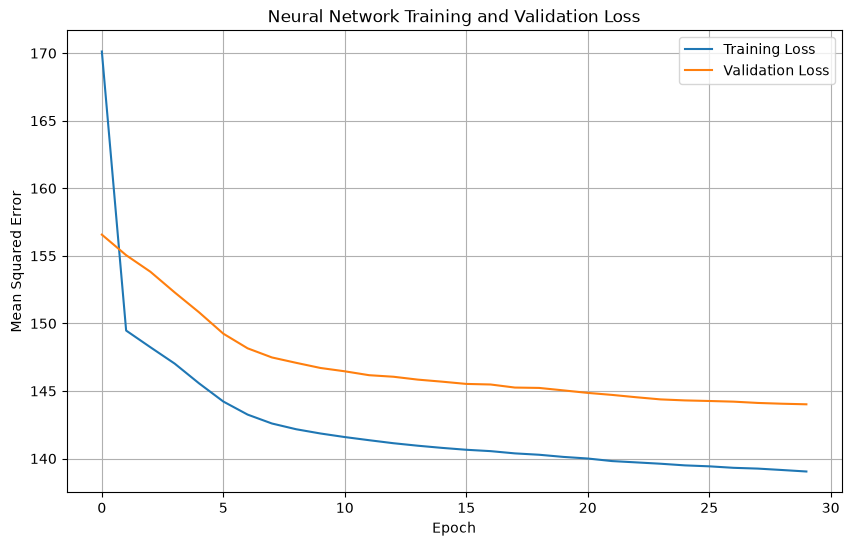

In [28]:
# Step 6: Plot neural network training history

plt.figure(figsize=(10, 6))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.show()

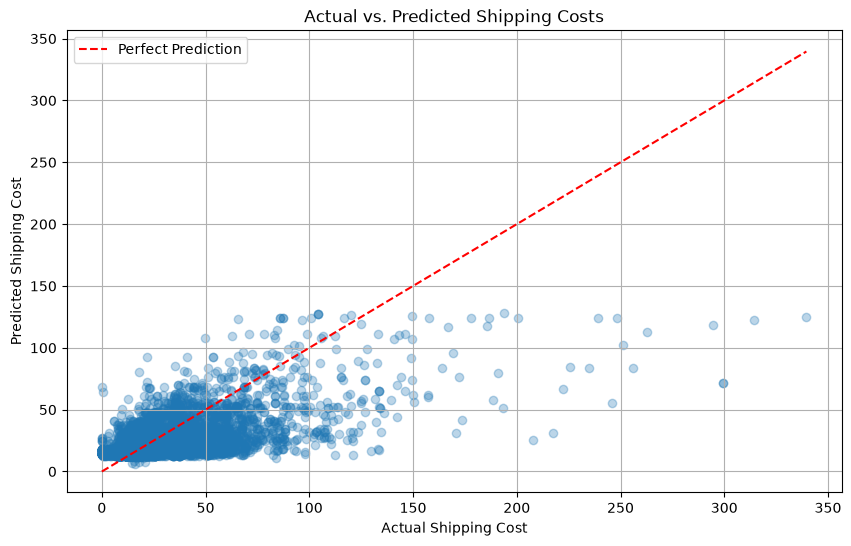

In [29]:

# Step 7: Actual vs. Predicted Shipping Costs

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred_nn, alpha=0.3)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_nn.min())
max_value = max(y_test.max(), y_pred_nn.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs. Predicted Shipping Costs")
plt.xlabel("Actual Shipping Cost")
plt.ylabel("Predicted Shipping Cost")
plt.legend()
plt.grid(True)

plt.show()


Neural Network Results and Interpretation

The neural network model was developed to predict e-commerce shipping costs using product weight, length, height, and width. The model was trained using 80% of the dataset and evaluated using the remaining 20%.

The neural network achieved an MAE of 6.5353, an RMSE of 12.0580, and an R-squared value of 0.4248. This indicates that the model explained approximately 42.48% of the variation in shipping costs.

The training and validation loss graph showed that both losses decreased throughout training, suggesting the model was learning without obvious signs of significant overfitting.

The actual versus predicted shipping costs graph showed that the model struggled to predict higher shipping costs accurately. This suggests that additional variables, such as shipping distance, delivery location, and shipping method, may improve future predictions.

Overall, the neural network demonstrated moderate predictive performance, but further improvements could make it more useful for estimating e-commerce shipping costs.

In [30]:
# Step 9: Check previous regression model results

# Find saved model performance variables
for name, value in globals().copy().items():
    if any(term in name.lower() for term in
           ["mae", "rmse", "r2", "mse"]):
        if isinstance(value, (int, float, np.number)):
            print(name, ":", round(float(value), 4))

linear_mae : 6.9083
linear_mse : 140.9218
linear_r2 : 0.4885
svr_mae : 7.1674
svr_mse : 208.3632
svr_r2 : 0.2437
nn_mae : 6.5353
nn_mse : 145.3964
nn_rmse : 12.058
nn_r2 : 0.4248


In [31]:
# Step 10: Compare regression models

comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Support Vector Regression",
        "Neural Network"
    ],
    "MAE": [linear_mae, svr_mae, nn_mae],
    "RMSE": [
        np.sqrt(linear_mse),
        np.sqrt(svr_mse),
        nn_rmse
    ],
    "R-squared": [linear_r2, svr_r2, nn_r2]
})

display(comparison_df.round(4))

,Model,MAE,RMSE,R-squared
0,Linear Regression,6.9083,11.8710,0.4885
1,Support Vector Regression,7.1674,14.4348,0.2437
2,Neural Network,6.5353,12.0580,0.4248


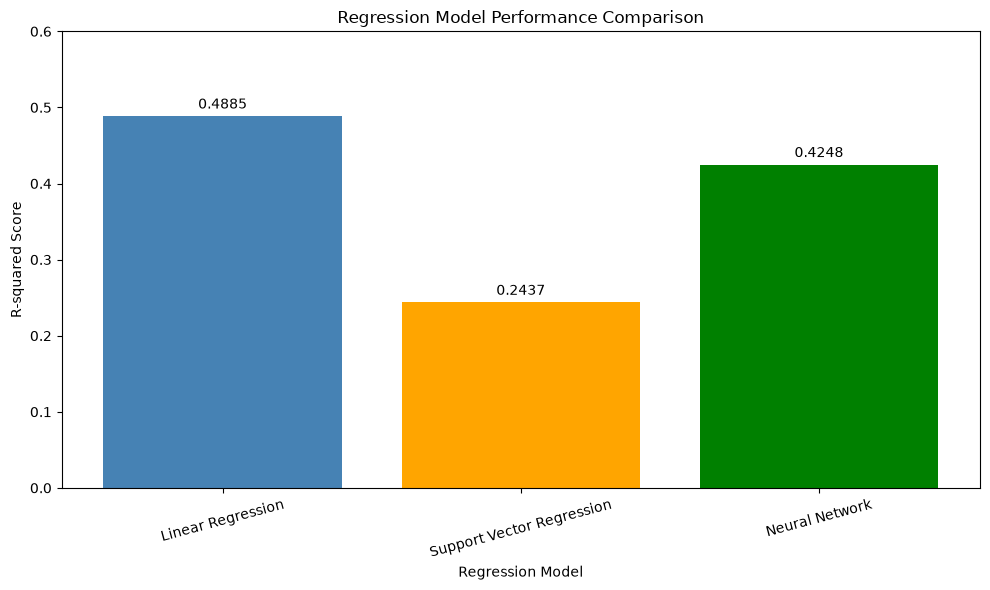

In [32]:

# Step 11: Compare Model R-squared Scores

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["R-squared"],
    color=["steelblue", "orange", "green"]
)

plt.title("Regression Model Performance Comparison")
plt.xlabel("Regression Model")
plt.ylabel("R-squared Score")
plt.ylim(0, 0.6)

for i, value in enumerate(comparison_df["R-squared"]):
    plt.text(i, value + 0.01, f"{value:.4f}",
             ha="center")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [33]:
# Step 12: Check model evaluation data

print("Neural Network Test Rows:", len(y_test))

# Check available test datasets
for name in ["X_test", "y_test",
             "X_test_scaled", "y_pred_nn"]:
    if name in globals():
        print(name, ":", len(globals()[name]))

# Check previous model prediction variables
for name in sorted(globals()):
    if "pred" in name.lower() and not name.startswith("_"):
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, "shape:", value.shape)

Neural Network Test Rows: 22527
X_test : 22527
y_test : 22527
X_test_scaled : 22527
y_pred_nn : 22527
linear_predictions shape: (1000,)
svr_predictions shape: (1000,)
y_pred_nn shape: (22527,)


In [34]:
# Step 13: Check test data consistency

print("Test target preview:")
print(y_test.head())

print("\nTest feature preview:")
print(X_test.head())

print("\nTest data dimensions:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Test target preview:
52009     22.85
33232     16.16
103208     8.55
24547     10.47
33578     15.24
Name: freight_value, dtype: float64

Test feature preview:
        product_weight_g  product_length_cm  product_height_cm  \
52009             1050.0               18.0               13.0   
33232              750.0               16.0               12.0   
103208             380.0               17.0               11.0   
24547              400.0               34.0                4.0   
33578              950.0               45.0               15.0   

        product_width_cm  
52009               10.0  
33232               15.0  
103208              13.0  
24547               22.0  
33578               35.0  

Test data dimensions:
X_test: (22527, 4)
y_test: (22527,)


In [38]:

# Step 14: Find existing prediction variables

print("Prediction variables found:")

for name, value in globals().copy().items():
    if "pred" in name.lower():
        if hasattr(value, "shape"):
            print(name, ":", value.shape)
        else:
            print(name, ":", type(value).__name__)

Prediction variables found:
linear_predictions : (1000,)
svr_predictions : (1000,)
y_pred_nn : (22527,)


In [39]:
# Step 15: Find test datasets

print("Available test variables:")

for name, value in globals().copy().items():
    if "test" in name.lower():
        if hasattr(value, "shape"):
            print(name, ":", value.shape)

Available test variables:
X_test : (22527, 4)
y_test : (22527,)
X_test_scaled : (22527, 4)


In [40]:
# Step 16: Find previously trained regression models

print("Available regression models:")

for name, value in globals().copy().items():
    if hasattr(value, "predict") and hasattr(value, "fit"):
        print(name, ":", type(value).__name__)

Available regression models:
LinearRegression : ABCMeta
SVR : ABCMeta
linear_model : LinearRegression
svr_model : SVR
model : Sequential


In [41]:
# Step 17: Check model input features

print("Linear Regression features:")
print(getattr(linear_model, "feature_names_in_", "Not stored"))
print("Number of features:",
      getattr(linear_model, "n_features_in_", "Unknown"))

print("\nSVR features:")
print(getattr(svr_model, "feature_names_in_", "Not stored"))
print("Number of features:",
      getattr(svr_model, "n_features_in_", "Unknown"))

print("\nNeural Network features:")
print(X_test.columns.tolist())

Linear Regression features:
['product_weight_g' 'product_length_cm' 'product_height_cm'
 'product_width_cm']
Number of features: 4

SVR features:
Not stored
Number of features: 4

Neural Network features:
['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [42]:
# Step 18: Check test data and model predictions

print("Test data rows:", len(X_test))
print("Actual shipping costs:", len(y_test))

print("\nLinear Regression predictions:")
linear_predictions = linear_model.predict(X_test)
print("Count:", len(linear_predictions))

print("\nNeural Network predictions:")
print("Count:", len(y_pred_nn))

print("\nSVR model:")
print("SVR uses", svr_model.n_features_in_, "features")

print("\nFeature order:")
print(X_test.columns.tolist())

Test data rows: 22527
Actual shipping costs: 22527

Linear Regression predictions:
Count: 22527

Neural Network predictions:
Count: 22527

SVR model:
SVR uses 4 features

Feature order:
['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [43]:

# Step 19: Check SVR predictions

print("SVR predictions:", len(svr_predictions))

print("Actual test values:", len(y_test))

print("\nPrediction counts match:",
      len(svr_predictions) == len(y_test))

SVR predictions: 1000
Actual test values: 22527

Prediction counts match: False


In [44]:

# Step 20: Check SVR model details

print("SVR model:", svr_model)

print("\nSVR predictions:")
print("Number of predictions:", len(svr_predictions))

print("\nCurrent test dataset:")
print("Number of observations:", len(X_test))

print("\nSVR feature count:")
print(svr_model.n_features_in_)

print("\nCurrent test features:")
print(X_test.columns.tolist())

SVR model: SVR()

SVR predictions:
Number of predictions: 1000

Current test dataset:
Number of observations: 22527

SVR feature count:
4

Current test features:
['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [45]:
# Step 21: Check SVR training information

print("SVR model:")
print(svr_model)

print("\nSVR training feature names:")
print(getattr(svr_model, "feature_names_in_", "Not stored"))

print("\nAvailable scaling variables:")

for name, value in globals().copy().items():
    if "scaler" in name.lower():
        print(name, ":", type(value).__name__)

SVR model:
SVR()

SVR training feature names:
Not stored

Available scaling variables:
StandardScaler : type
scaler : StandardScaler


In [46]:
# Step 22: Check SVR training setup

print("SVR training information:")

print("Number of support vectors:",
      svr_model.support_vectors_.shape[0])

print("\nFirst 5 support vectors:")
print(svr_model.support_vectors_[:5])

print("\nCurrent unscaled features:")
print(X_test.head())

print("\nCurrent scaled features:")
print(X_test_scaled[:5])

SVR training information:
Number of support vectors: 3906

First 5 support vectors:
[[-0.51574983 -0.86719993 -0.938863   -0.85156551]
 [-0.14846367  0.62816036  0.6340855  -0.2537959 ]
 [-0.52255143 -0.68027989 -0.86396069 -1.02235683]
 [ 0.42287037  1.87429393 -0.33964452  0.60016069]
 [-0.37971792 -0.86719993 -0.71415607 -0.85156551]]

Current unscaled features:
        product_weight_g  product_length_cm  product_height_cm  \
52009             1050.0               18.0               13.0   
33232              750.0               16.0               12.0   
103208             380.0               17.0               11.0   
24547              400.0               34.0                4.0   
33578              950.0               45.0               15.0   

        product_width_cm  
52009               10.0  
33232               15.0  
103208              13.0  
24547               22.0  
33578               35.0  

Current scaled features:
[[-0.27821782 -0.75195415 -0.26837961 -1.110367

In [47]:
# Step 23: Compare available scalers

for name in ["standard_scaler", "scaler"]:
    if name in globals():
        s = globals()[name]
        print("\nScaler:", name)
        print("Fitted:", hasattr(s, "mean_"))

        if hasattr(s, "mean_"):
            print("Means:", s.mean_)
            print("Scales:", s.scale_)

print("\nSVR model gamma:")
print(svr_model.gamma)


Scaler: scaler
Fitted: True
Means: [2095.67784252   30.16298763   16.60830143   22.98301981]
Scales: [3758.48622321   16.17517184   13.44476743   11.69254505]

SVR model gamma:
scale


In [48]:

# Step 24: Verify SVR prediction counts

print("Actual test values:", len(y_test))
print("SVR predictions:", len(svr_predictions))

print("\nPrediction counts match:")
print(len(y_test) == len(svr_predictions))

Actual test values: 22527
SVR predictions: 1000

Prediction counts match:
False


In [49]:

# Step 25: Generate SVR predictions for the full test dataset

svr_predictions = svr_model.predict(X_test_scaled)

print("Actual test values:", len(y_test))
print("SVR predictions:", len(svr_predictions))

print("\nPrediction counts match:")
print(len(y_test) == len(svr_predictions))

Actual test values: 22527
SVR predictions: 22527

Prediction counts match:
True


In [50]:
# Step 26: Recalculate SVR performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

svr_mae = mean_absolute_error(y_test, svr_predictions)
svr_mse = mean_squared_error(y_test, svr_predictions)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test, svr_predictions)

print("Updated Support Vector Regression Results:")
print("MAE:", round(svr_mae, 4))
print("MSE:", round(svr_mse, 4))
print("RMSE:", round(svr_rmse, 4))
print("R-squared:", round(svr_r2, 4))

Updated Support Vector Regression Results:
MAE: 6.8334
MSE: 198.6005
RMSE: 14.0926
R-squared: 0.2143


In [51]:
# Step 27: Updated regression model comparison

comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Support Vector Regression",
        "Neural Network"
    ],
    "MAE": [linear_mae, svr_mae, nn_mae],
    "RMSE": [
        np.sqrt(linear_mse),
        np.sqrt(svr_mse),
        np.sqrt(nn_mse)
    ],
    "R-squared": [linear_r2, svr_r2, nn_r2]
})

display(comparison_df.round(4))

,Model,MAE,RMSE,R-squared
0,Linear Regression,6.9083,11.8710,0.4885
1,Support Vector Regression,6.8334,14.0926,0.2143
2,Neural Network,6.5353,12.0580,0.4248


Model Comparison and Interpretation

Three regression models were evaluated to predict e-commerce shipping costs: Linear Regression, Support Vector Regression (SVR), and a Neural Network.

Linear Regression achieved the highest R-squared value of 0.4885, explaining approximately 48.85% of the variation in shipping costs. It also produced the lowest RMSE of 11.8710, indicating better performance when larger prediction errors are penalized.

The Neural Network achieved the lowest Mean Absolute Error (MAE) of 6.5353, suggesting that it performed slightly better in terms of average absolute prediction error. Its R-squared value was 0.4248.

Support Vector Regression had the lowest R-squared value of 0.2143, indicating that it explained less variation in shipping costs than the other two models.

Overall, Linear Regression was selected as the strongest model based on its higher R-squared value and lower RMSE. However, the results suggest that additional features and model improvements could help increase prediction accuracy.

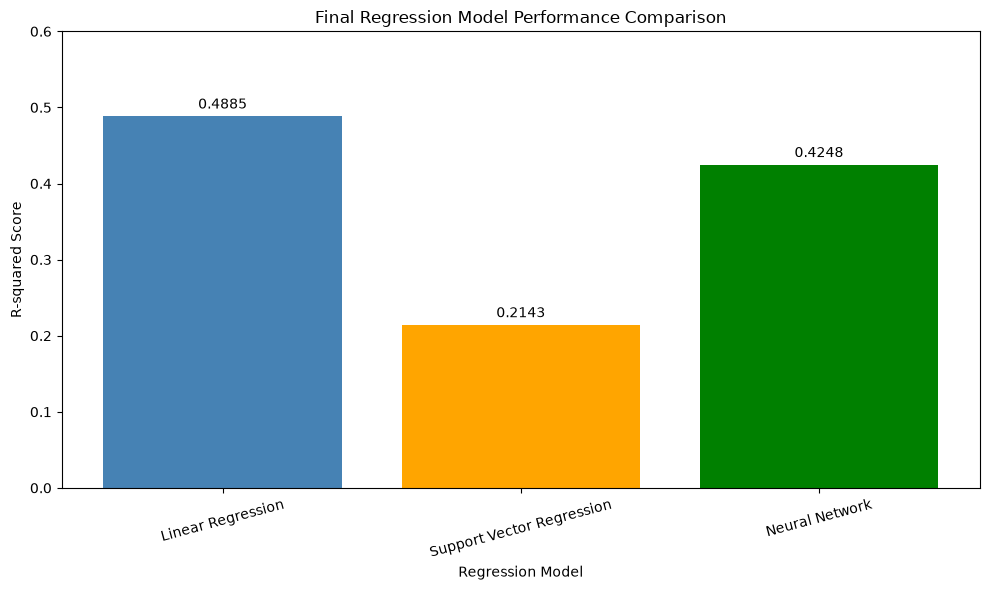

In [52]:
# Step 29: Updated regression model performance graph

import matplotlib.pyplot as plt

models = comparison_df["Model"]
r2_values = comparison_df["R-squared"]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    models,
    r2_values,
    color=["steelblue", "orange", "green"]
)

plt.title("Final Regression Model Performance Comparison")
plt.xlabel("Regression Model")
plt.ylabel("R-squared Score")
plt.ylim(0, 0.6)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.4f}",
        ha="center"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Final Project Conclusion

The purpose of this project was to evaluate different machine learning models for predicting e-commerce shipping costs using product characteristics. Three models were developed and compared: Linear Regression, Support Vector Regression, and a Neural Network.

The results showed that Linear Regression achieved the highest R-squared value of 0.4885 and the lowest RMSE of 11.8710. The Neural Network achieved the lowest MAE of 6.5353, while Support Vector Regression had the lowest overall R-squared value.

Based on these findings, Linear Regression was selected as the strongest overall model. However, the results also demonstrated that product characteristics alone do not fully explain shipping costs.

Future improvements could include additional variables such as shipping distance, delivery location, transportation method, and delivery speed. These factors may help improve the accuracy of future shipping cost predictions.

Overall, this project demonstrated how machine learning techniques can be used to analyze shipping costs and support data-driven decision-making in e-commerce and logistics.

## Step 5: Act — Business Recommendations

Based on the results of this project, Linear Regression was the strongest overall model for predicting e-commerce shipping costs. It achieved the highest R-squared value (0.4885) and the lowest RMSE (11.8710). However, the Neural Network achieved the lowest MAE (6.5353), showing that different models may perform better depending on the evaluation metric.

An e-commerce or logistics company could use these findings to explore ways to estimate shipping expenses, plan budgets, and make more informed pricing decisions. Before using the models in real business operations, additional testing would be necessary because the current models do not explain all the variation in shipping costs.

Future improvements could include adding shipping distance, delivery location, transportation method, package weight, and delivery speed. These additional variables may improve prediction accuracy.

The recommended next step is to improve the dataset, retrain the models, and evaluate their performance on new data before considering deployment.